# Practical Session 09 &mdash; B. Bagging and random forests

A team of trees beats one tree when the trees are **right on average, jumpy, and different from each
other**. But we only have **one** dataset. This notebook builds such a team from it, in three steps:
**resample** the data, **train** a deep tree on each resample, **combine** their answers. That recipe
is called bagging. A random forest adds one more trick to make the trees even more different.

| | Notebook | What you do |
|---|---|---|
| A | Why a team beats its members | a guessing crowd, voting by hand, counting, averaging |
| **B** | **Bagging and random forests** | **build a team from one dataset; the out-of-bag score; random features (this notebook)** |
| C | Boosting, and teams of any model | AdaBoost and gradient boosting by hand; any model inside; choosing |

> &#11088; **Key idea.** **Bagging** = **B**ootstrap **AGG**regat**ING**: train many models, each on
> its own bootstrap sample of the one dataset, and let them vote (or average). **Any model** can go
> inside; deep trees are the usual choice. A **random forest** works with **trees only**: it is bagged
> trees plus one change, at every split a tree may look only at a random handful of the features.

The bootstrap and a small bagged team are written by hand on ten points. Then the out-of-bag score is
counted by hand from a fitted `BaggingClassifier` and checked against its own `oob_score_`. Everything
larger uses scikit-learn's `BaggingClassifier`, `BaggingRegressor` and `RandomForestClassifier`.

*Run the cells in order (Shift+Enter). Self-contained and offline; the whole notebook runs in about
one minute.*

In [1]:
import itertools
from collections import Counter

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.ensemble import BaggingClassifier, BaggingRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

from nb_utils import use_style
from nb_data import make_noisy_wave, make_ten_points, noisy_wave_truth, sample_noisy_wave

use_style("notes")
C0, C1, CG, CN = "#0072B2", "#D55E00", "#009E73", "#E69F00"
CP = "#CC79A7"                   # pink, when a fifth color is needed
CX = "0.62"                      # gray, for reference lines
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=[C0, C1, CG, CN, CP])   # frozen palette


def plot_regions(ax, predict, X, y, lim, title="", s=16):
    "shade the region each class gets from predict(); circles = class 0, squares = class 1"
    (a1, b1), (a2, b2) = lim
    g1, g2 = np.meshgrid(np.linspace(a1, b1, 300), np.linspace(a2, b2, 300))
    Z = predict(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)
    ax.contourf(g1, g2, Z, levels=[-0.5, 0.5, 1.5], colors=[C0, C1], alpha=0.15)
    for lab, c, mk in ((0, C0, "o"), (1, C1, "s")):
        ax.scatter(*X[y == lab].T, s=s, color=c, marker=mk, edgecolor="white", linewidth=0.4)
    ax.set_xlim(a1, b1); ax.set_ylim(a2, b2)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(title, fontsize=10)


print("ready")

ready


## 1. Where do 100 datasets come from? The bootstrap

We have **one** dataset. The trick is to draw new ones **from it**: draw $n$ examples **with
replacement**, putting each one back before the next draw. The new dataset has the same size $n$, but
some examples come out twice or three times, and some never.

**Your turn first:** take ten numbered cards (or a 10-sided die). Draw ten times, putting the card back
each time. How many numbers never came out?

The cell draws three such resamples of ten cards. Then it asks how many cards are left out **on
average**: a card is missed by one draw with probability $1-\frac1n$, and by all $n$ independent draws
with probability $\left(1-\frac1n\right)^n$. A simulation of 100,000 resamples checks the formula.

resample 1: cards drawn [1, 1, 2, 3, 4, 5, 5, 9, 9, 10]
            times each card came out [2, 1, 1, 1, 2, 0, 0, 0, 2, 1] -> never: [6, 7, 8] (3 of 10)
resample 2: cards drawn [1, 5, 5, 6, 6, 7, 7, 8, 8, 9]
            times each card came out [1, 0, 0, 0, 2, 2, 2, 2, 1, 0] -> never: [2, 3, 4, 10] (4 of 10)
resample 3: cards drawn [1, 3, 4, 6, 7, 7, 7, 8, 8, 10]
            times each card came out [1, 0, 1, 1, 0, 1, 3, 2, 0, 1] -> never: [2, 5, 9] (3 of 10)

share of the cards left out, n = 10: formula 34.9%, simulation of 100,000 resamples 34.9%
share left out, n = 180: 36.7%
share left out, n = 10,000: 36.8%
(the limit for large n is 1/e = 36.8%)
resamples that leave out 2 to 5 of the 10 cards: 97%


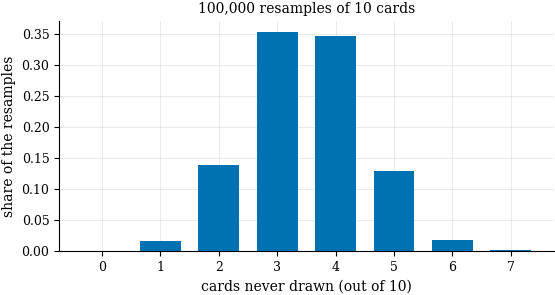

In [2]:
n = 10
rng = np.random.default_rng(2489)                 # <-- CHANGE ME: other draws
for b in range(3):
    idx = rng.integers(0, n, n)                    # n draws with replacement: 0 = card 1, ..., 9 = card 10
    counts = np.bincount(idx, minlength=n)
    if n <= 20:                                    # small enough to read card by card
        print(f"resample {b + 1}: cards drawn {sorted((idx + 1).tolist())}")
        print(f"            times each card came out {counts.tolist()} -> never: "
              f"{(np.flatnonzero(counts == 0) + 1).tolist()} ({np.sum(counts == 0)} of {n})")
    else:
        print(f"resample {b + 1}: {np.sum(counts == 0)} of the {n} cards never came out")

# on average: the exact formula, and a simulation (each row of `draws` is one resample)
draws = np.sort(np.random.default_rng(0).integers(0, n, (100_000, n)), axis=1)
distinct = 1 + np.sum(np.diff(draws, axis=1) != 0, axis=1)      # sorted: a new card wherever the value changes
print(f"\nshare of the cards left out, n = {n}: formula {(1 - 1 / n) ** n:.1%}, "
      f"simulation of 100,000 resamples {1 - distinct.mean() / n:.1%}")
for m in (180, 10_000):
    print(f"share left out, n = {m:,}: {(1 - 1 / m) ** m:.1%}")
print(f"(the limit for large n is 1/e = {np.exp(-1):.1%})")
left_out = n - distinct
lo, hi = round(0.2 * n), round(0.5 * n)                         # 2 to 5 cards when n = 10
print(f"resamples that leave out {lo} to {hi} of the {n} cards: "
      f"{np.mean((left_out >= lo) & (left_out <= hi)):.0%}")

fig, ax = plt.subplots(figsize=(5.6, 3.0))
k, c = np.unique(left_out, return_counts=True)
ax.bar(k, c / len(left_out), color=C0, width=0.7)
ax.set_xlabel(f"cards never drawn (out of {n})")
ax.set_ylabel("share of the resamples")
ax.set_title(f"100,000 resamples of {n} cards", fontsize=10)
plt.show()

Each resample leaves out **a bit over a third** of the examples: 34.9% on average with ten examples
(formula and simulation agree), 36.8% with many. Here the three resamples left out 3, 4 and 3 of the
ten cards, and the bar chart shows the usual range: 97% of the resamples leave out 2 to 5 cards.
Remember the left-out examples: they come back in section 3.

## 2. Bagging by hand: the ten points

**Bagging** = **B**ootstrap **AGG**regat**ING**, in three steps:

1. **resample:** draw $B$ bootstrap samples of the training data;
2. **train:** fit one deep tree on each sample;
3. **combine:** let the trees vote (classification) or average their predictions (regression).

Each tree sees a slightly different dataset, so each makes **different mistakes**. Here is bagging on
ten small points (two features, two classes: circle = 0, square = 1), with $B=5$: the same three
resamples as above, plus two more. A tree's first question is printed with the group of points it
sends to the left. In the pictures, filled points are in that tree's sample and hollow points were left
out of it.

tree 1: first question x1 <= 8.5  -> sends left the points (1, 2, 3, 4, 5, 6, 7, 8)
tree 2: first question x2 <= 5.0  -> sends left the points (1, 2, 4, 5, 8)
tree 3: first question x1 <= 3.5  -> sends left the points (1, 2, 3)
tree 4: first question x1 <= 3.5  -> sends left the points (1, 2, 3)
tree 5: first question x1 <= 3.0  -> sends left the points (1, 2, 3)
different first splits (different groups sent left): 3

votes for class 1, point by point: [0, 1, 1, 1, 1, 4, 4, 3, 5, 5]
the majority vote of the 5 trees is right on 10 of the 10 points


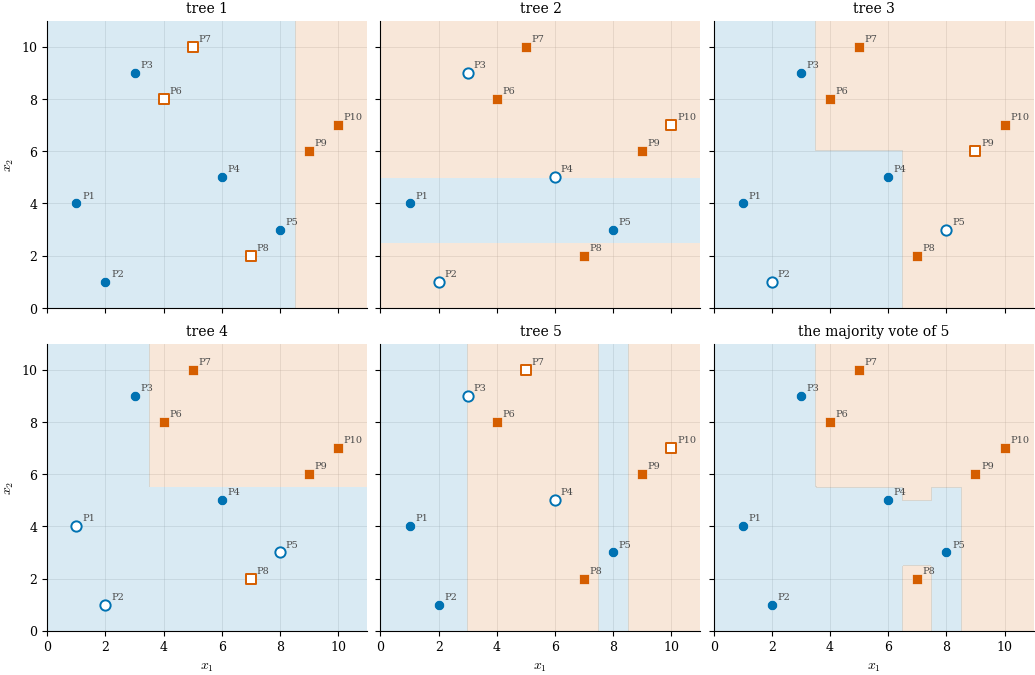

In [3]:
X10, y10 = make_ten_points()
B = 5
rng = np.random.default_rng(2489)            # the same three resamples as in section 1, plus two more
samples, trees10 = [], []
for b in range(B):
    idx = rng.integers(0, 10, 10)            # step 1: a bootstrap sample
    samples.append(idx)
    trees10.append(DecisionTreeClassifier(random_state=0).fit(X10[idx], y10[idx]))   # step 2: a deep tree

firsts = []
for b, tree in enumerate(trees10):
    if tree.tree_.node_count == 1:                                  # its sample holds one class only
        print(f"tree {b + 1}: no question at all (its sample holds one class only)")
        continue
    j, t = tree.tree_.feature[0], tree.tree_.threshold[0]           # the first question: x_j <= t ?
    left = tuple(int(i) for i in np.flatnonzero(X10[:, j] <= t) + 1)
    firsts.append(left)
    print(f"tree {b + 1}: first question x{j + 1} <= {t:.1f}  -> sends left the points {left}")
print(f"different first splits (different groups sent left): {len(set(firsts))}")

votes = np.array([tree.predict(X10) for tree in trees10])          # one row per tree
team = (votes.sum(axis=0) > B / 2).astype(int)                      # step 3: the majority vote
print(f"\nvotes for class 1, point by point: {votes.sum(axis=0).tolist()}")
print(f"the majority vote of the {B} trees is right on {np.sum(team == y10)} of the 10 points")


def vote_of(trees):
    "the predict() of a team: the majority vote of the trees"
    return lambda Z: (np.mean([t.predict(Z) for t in trees], axis=0) > 0.5).astype(int)


fig, axes = plt.subplots(2, 3, figsize=(10.4, 6.8), sharex=True, sharey=True)
lim = ((0, 11), (0, 11))
for b, ax in enumerate(axes.flat[:B]):
    inbag = np.isin(np.arange(10), samples[b])
    plot_regions(ax, trees10[b].predict, X10[inbag], y10[inbag], lim, s=55, title=f"tree {b + 1}")
    for lab, c, mk in ((0, C0, "o"), (1, C1, "s")):                  # left out: hollow
        sel = ~inbag & (y10 == lab)
        ax.scatter(*X10[sel].T, s=55, marker=mk, facecolor="white", edgecolor=c, linewidth=1.4)
plot_regions(axes.flat[B], vote_of(trees10), X10, y10, lim, s=55, title=f"the majority vote of {B}")
for ax in axes.flat:
    for i, (u, v) in enumerate(X10):
        ax.annotate(f"P{i + 1}", (u, v), (4, 4), textcoords="offset points", fontsize=7, color="0.3")
    if ax not in axes[:, 0]:
        ax.set_ylabel("")
    if ax not in axes[1]:
        ax.set_xlabel("")
plt.show()

Five trees, three different first splits. Trees 3, 4 and 5 all separate P1&ndash;P3 from the rest;
their thresholds differ (3.5 or 3.0) only because a bootstrap sample has different gaps between its
points. The majority vote of the five is right on all ten points... but most of the trees were trained
on those very points. Is that an honest score?

## 3. An honest score for free: out-of-bag

Each point was **left out** by some of the trees. Let **only those trees** judge it: they never saw the
point, so for them it is a test point. If the judges split their votes evenly, the tie goes to class 0
(circle); section 3's second cell checks that scikit-learn breaks ties the same way.

In [4]:
inbag = np.array([np.isin(np.arange(10), s) for s in samples])     # (B, 10): True = in tree b's sample
oob_pred = np.full(10, -1)                                         # -1 = no judge
for i in range(10):
    judges = np.flatnonzero(~inbag[:, i])                          # the trees that never saw point i
    if len(judges) == 0:
        print(f"P{i + 1:<2d} (class {y10[i]}): in every tree's sample, so it has no judge")
        continue
    n1 = int(votes[judges, i].sum())
    n0 = len(judges) - n1
    oob_pred[i] = int(n1 > n0)                                     # a tie goes to class 0
    print(f"P{i + 1:<2d} (class {y10[i]}): judged by trees {(judges + 1).tolist()}, votes 0:{n0} 1:{n1} -> "
          f"{oob_pred[i]} {'right' if oob_pred[i] == y10[i] else 'WRONG'}" + ("  (a tie)" if n0 == n1 else ""))
print(f"out-of-bag: right on {np.sum(oob_pred == y10)} of the {np.sum(oob_pred >= 0)} judged points "
      f"(the full vote: {np.sum(team == y10)} of 10)")

P1  (class 0): judged by trees [4], votes 0:1 1:0 -> 0 right
P2  (class 0): judged by trees [2, 3, 4], votes 0:2 1:1 -> 0 right
P3  (class 0): judged by trees [2, 5], votes 0:1 1:1 -> 0 right  (a tie)
P4  (class 0): judged by trees [2, 5], votes 0:1 1:1 -> 0 right  (a tie)
P5  (class 0): judged by trees [3, 4], votes 0:1 1:1 -> 0 right  (a tie)
P6  (class 1): judged by trees [1], votes 0:1 1:0 -> 0 WRONG
P7  (class 1): judged by trees [1, 5], votes 0:1 1:1 -> 0 WRONG  (a tie)
P8  (class 1): judged by trees [1, 4], votes 0:2 1:0 -> 0 WRONG
P9  (class 1): judged by trees [3], votes 0:0 1:1 -> 1 right
P10 (class 1): judged by trees [2, 5], votes 0:0 1:2 -> 1 right
out-of-bag: right on 7 of the 10 judged points (the full vote: 10 of 10)


On the ten points the out-of-bag judges get **7 of 10** right, not 10 of 10. Four points (P3, P4, P5
and P7) have two judges who disagree, so the tie rule decides them.

**The same at full size.** A fitted `BaggingClassifier` remembers the sample each of its trees was
trained on (`estimators_samples_`), so its out-of-bag votes can be counted by hand and compared with its
own `oob_score_`. The cell does it three times: on the **two moons** (300 points: 180 for training, 120
for testing) with 300 bagged trees; on a small 5-tree bag of the ten points whose out-of-bag votes
contain a tie, to check the tie rule; and on 10 draws of the moons, to compare the out-of-bag score
with the test accuracy more than once.

In [5]:
def oob_votes(bag, X):
    "for every training point, the votes of the trees that never saw it (columns: class 0, class 1)"
    votes = np.zeros((len(X), 2))
    for tree, sample in zip(bag.estimators_, bag.estimators_samples_):
        out = np.ones(len(X), dtype=bool)
        out[sample] = False                             # the points this tree never saw
        votes[np.flatnonzero(out), tree.predict(X[out]).astype(int)] += 1
    return votes


X, y = make_moons(n_samples=300, noise=0.32, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)
bag = BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=300, oob_score=True,
                        random_state=0).fit(Xtr, ytr)
v = oob_votes(bag, Xtr)
print(f"moons, 300 bagged trees: every training point is judged by {int(v.sum(axis=1).min())} "
      f"to {int(v.sum(axis=1).max())} trees")
print(f"out-of-bag accuracy by hand {np.mean(v.argmax(axis=1) == ytr):.4f} (argmax: a tie goes to class 0), "
      f"scikit-learn's oob_score_ {bag.oob_score_:.4f}; test accuracy {bag.score(Xte, yte):.4f}")

small = BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=5, oob_score=True,
                          random_state=51).fit(X10, y10)
v = oob_votes(small, X10)
tie = v[:, 0] == v[:, 1]
print(f"\na 5-tree bag of the ten points, with {tie.sum()} tied point: out-of-bag accuracy "
      f"{np.mean(v.argmax(axis=1) == y10):.1f} with ties to circle, "
      f"{np.mean(np.where(tie, 1, v.argmax(axis=1)) == y10):.1f} with ties to square; "
      f"scikit-learn's oob_score_ {small.oob_score_:.1f}")

gaps = []                                               # one split can be lucky: 10 draws of the moons
for s in range(10):
    Xs, ys = make_moons(n_samples=300, noise=0.32, random_state=s)
    Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.4, random_state=s, stratify=ys)
    bag_s = BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=300, oob_score=True,
                              random_state=0).fit(Xs_tr, ys_tr)
    gaps.append(bag_s.oob_score_ - bag_s.score(Xs_te, ys_te))
print(f"\n10 draws of the moons: out-of-bag minus test accuracy from {min(gaps):+.3f} to {max(gaps):+.3f} "
      f"(one test point is worth {1 / len(ys_te):.3f})")

moons, 300 bagged trees: every training point is judged by 87 to 134 trees
out-of-bag accuracy by hand 0.9111 (argmax: a tie goes to class 0), scikit-learn's oob_score_ 0.9111; test accuracy 0.9083

a 5-tree bag of the ten points, with 1 tied point: out-of-bag accuracy 0.6 with ties to circle, 0.5 with ties to square; scikit-learn's oob_score_ 0.6



10 draws of the moons: out-of-bag minus test accuracy from -0.036 to +0.069 (one test point is worth 0.008)


On the moons, the hand-made out-of-bag accuracy is 0.9111, exactly scikit-learn's `oob_score_`, and the
test accuracy is 0.9083. On the small bag, scikit-learn's score is the one with the tie sent to the
circle (0.6, not 0.5): the same rule as ours.

The out-of-bag score is a **free validation set**: no data is held back for it. On the first split it
agreed closely with the test accuracy, but that was partly luck: over 10 draws, out-of-bag minus test
runs from -0.036 to +0.069. A 120-point test set is noisy too, so read both as estimates; the
out-of-bag one costs no data. In scikit-learn it is one argument: `oob_score=True`.

## 4. Bagging on the moons

One fully grown tree on all 180 training points, then teams of 10 and 100 bagged trees. Their
boundaries are drawn below. One split of the data can be lucky, so the cell then repeats the
comparison on the 10 draws of the moons used in section 3 (the first is the split above, the other 9
are fresh).

**Predict first:** will 100 bagged trees score higher than 10?

one tree         test accuracy 0.867 (104 of 120 test points)
10 bagged trees  test accuracy 0.875 (105 of 120 test points)


100 bagged trees test accuracy 0.908 (109 of 120 test points)


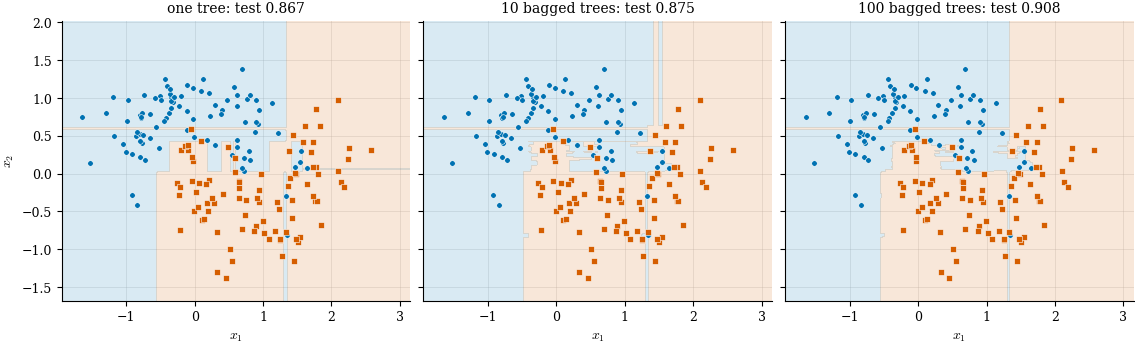


over 10 draws of the moons:
  one tree         mean test accuracy 0.837 +/- 0.035
  10 bagged trees  mean test accuracy 0.865 +/- 0.027
  100 bagged trees mean test accuracy 0.870 +/- 0.026
  10 bagged trees vs one tree: better on 10, tied on 0, worse on 0 of 10 draws (largest loss: 0 of 120 test points)
  100 bagged trees vs 10 bagged trees: better on 4, tied on 3, worse on 3 of 10 draws (largest loss: 1 of 120 test points)


In [6]:
models = {"one tree": DecisionTreeClassifier(random_state=0)}
for B in (10, 100):                                    # <-- CHANGE ME: other team sizes
    models[f"{B} bagged trees"] = BaggingClassifier(DecisionTreeClassifier(random_state=0),
                                                    n_estimators=B, random_state=0)

lim = ((X[:, 0].min() - 0.3, X[:, 0].max() + 0.3), (X[:, 1].min() - 0.3, X[:, 1].max() + 0.3))
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.5), sharey=True)
for k, (ax, (name, model)) in enumerate(zip(axes, models.items())):
    acc = model.fit(Xtr, ytr).score(Xte, yte)
    print(f"{name:16s} test accuracy {acc:.3f} ({round(acc * len(yte))} of {len(yte)} test points)")
    plot_regions(ax, model.predict, Xtr, ytr, lim, title=f"{name}: test {acc:.3f}")
    if k:
        ax.set_ylabel("")
plt.show()

# one split can be lucky: the same comparison on 10 draws (the first is the split above)
scores = []
for s in range(10):
    Xs, ys = make_moons(n_samples=300, noise=0.32, random_state=s)
    Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.4, random_state=s, stratify=ys)
    scores.append([model.fit(Xs_tr, ys_tr).score(Xs_te, ys_te) for model in models.values()])
scores = np.array(scores)                              # one row per draw, one column per model
names = list(models)
print("\nover 10 draws of the moons:")
for k, name in enumerate(names):
    print(f"  {name:16s} mean test accuracy {scores[:, k].mean():.3f} +/- {scores[:, k].std(ddof=1):.3f}")
for a, b in ((0, 1), (1, 2)):
    d = scores[:, b] - scores[:, a]
    loss = round(max(0, -d.min()) * len(ys_te))       # the largest loss, in test points
    print(f"  {names[b]} vs {names[a]}: better on {np.sum(d > 0)}, tied on {np.sum(d == 0)}, "
          f"worse on {np.sum(d < 0)} of 10 draws (largest loss: {loss} of {len(ys_te)} test points)")

On this split: one tree 0.867, ten bagged trees 0.875, a hundred 0.908, that is, 4 more of the 120 test
points right than with ten. Look at the boundaries too: with 100 trees the boundary in the crowded
middle is a finer staircase than the single tree's blocks. Thin strips around a few isolated noisy
points survive, though: each point is in about two thirds of the bootstrap samples, so most trees
still carve a strip around it, and the vote keeps it.

Over 10 draws the picture is more honest. Ten bagged trees beat one tree on all 10 draws (0.837 to
0.865 on average). Going from 10 to 100 trees is better on 4 draws, tied on 3 and worse on 3 (0.865 to
0.870): most of the gain comes from the first few trees, and more trees mainly make the team **more
stable**. Section 6 measures that.

## 5. When bagging does not help

Now regression, on the **noisy wave**: 90 points with $y=\sin(1.4x)+0.3x$ plus noise. Because we know
the true curve, the **test error** is measured against the curve itself: the mean squared difference on
600 evenly spaced points between $-3$ and $3$.

We bag two very different models, with 100 copies each: a **linear regression** (a straight line) and a
**deep tree**. `BaggingRegressor` takes any model as its `estimator`; everything else is the same.

**Predict first:** which one will improve the most?

linear regression  test error alone 0.4390, bagged 0.4408 (+0.4%)


deep tree          test error alone 0.0933, bagged 0.0413 (-55.7%)


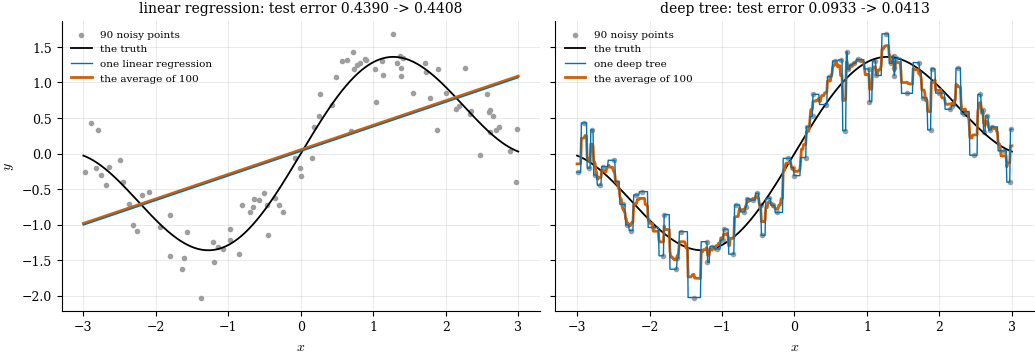

linear regression  over 10 training sets: error change +0.1% on average (from -0.6% to +1.6%), lower on 5 of 10


deep tree          over 10 training sets: error change -55.0% on average (from -61.5% to -46.7%), lower on 10 of 10


In [7]:
x, y_wave = make_noisy_wave()                    # the 90 training points
grid = np.linspace(-3, 3, 600)
truth = noisy_wave_truth(grid)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.6), sharey=True)
for ax, (name, base) in zip(axes, (("linear regression", LinearRegression()),
                                   ("deep tree", DecisionTreeRegressor(random_state=0)))):
    alone = base.fit(x[:, None], y_wave).predict(grid[:, None])
    bagger = BaggingRegressor(base, n_estimators=100, random_state=0).fit(x[:, None], y_wave)
    bagged = bagger.predict(grid[:, None])
    err_alone, err_bagged = np.mean((alone - truth) ** 2), np.mean((bagged - truth) ** 2)
    print(f"{name:18s} test error alone {err_alone:.4f}, bagged {err_bagged:.4f} "
          f"({100 * (err_bagged / err_alone - 1):+.1f}%)")
    ax.scatter(x, y_wave, s=9, color=CX, label="90 noisy points")
    ax.plot(grid, truth, color="k", lw=1.3, label="the truth")
    ax.plot(grid, alone, color=C0, lw=1.0, label=f"one {name}", zorder=3)
    ax.plot(grid, bagged, color=C1, lw=2.0, label="the average of 100")
    ax.set_title(f"{name}: test error {err_alone:.4f} -> {err_bagged:.4f}", fontsize=10)
    ax.set_xlabel("$x$")
    ax.legend(fontsize=7.5, loc="upper left")
axes[0].set_ylabel("$y$")
plt.show()

# one dataset can be lucky: the same comparison on 10 training sets of the wave (the first is the one above)
for name, base in (("linear regression", LinearRegression()),
                   ("deep tree", DecisionTreeRegressor(random_state=0))):
    change = []
    for s in range(10):
        xs, ys = make_noisy_wave(seed=s)
        alone = np.mean((base.fit(xs[:, None], ys).predict(grid[:, None]) - truth) ** 2)
        bagger = BaggingRegressor(base, n_estimators=100, random_state=0).fit(xs[:, None], ys)
        change.append(100 * (np.mean((bagger.predict(grid[:, None]) - truth) ** 2) / alone - 1))
    print(f"{name:18s} over 10 training sets: error change {np.mean(change):+.1f}% on average "
          f"(from {min(change):+.1f}% to {max(change):+.1f}%), lower on {np.sum(np.array(change) < 0)} of 10")

**Linear regression:** the average of 100 straight lines is a straight line. Nothing improves: here the
error even rises by 0.4%, and over 10 training sets it changes by +0.1% on average, lower on only
5 of them. The line's problem is **bias** (it is too simple to bend), not variance, and averaging
cannot fix bias. **Deep tree:** the error drops by 55.7% here, and it drops on all 10 training sets
(by 55.0% on average). Its problem *was* variance.

So bagging takes **any** model (here a straight line and a tree), but only **unstable** models gain.
Bagging a stable model is wasted computation. That is why bagging is almost always used with deep trees.

## 6. Check yourself: 1,000 trees instead of 100?

A bagged model with 100 trees works well. A friend wants 1,000 trees. Can the extra trees make the
model **overfit**?

**Predict first,** then run the cell. It fits 300 bagged trees once and computes the test error of the
average of the first $b$ trees, for every $b$ from 1 to 300.

    1 trees: test error 0.1054
   10 trees: test error 0.0488
  100 trees: test error 0.0413
  300 trees: test error 0.0415
from 100 trees on, the error stays between 0.0402 and 0.0415


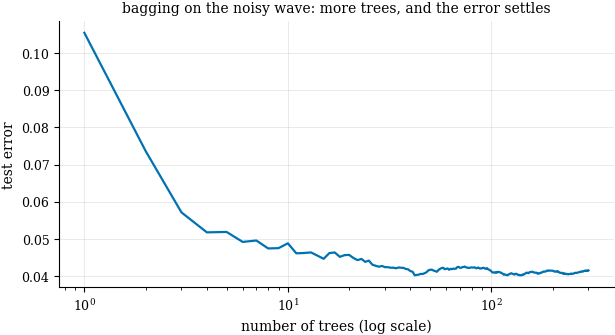

In [8]:
M = 300                                          # <-- CHANGE ME: try 1000 (about 3 seconds)
bag_wave = BaggingRegressor(DecisionTreeRegressor(random_state=0), n_estimators=M,
                            random_state=0).fit(x[:, None], y_wave)
P = np.array([tree.predict(grid[:, None]) for tree in bag_wave.estimators_])   # one row per tree
team_so_far = np.cumsum(P, axis=0) / np.arange(1, M + 1)[:, None]          # average of the first b trees
err = np.mean((team_so_far - truth) ** 2, axis=1)
for b in (1, 10, 100, M):
    print(f"{b:5d} trees: test error {err[b - 1]:.4f}")
print(f"from 100 trees on, the error stays between {err[99:].min():.4f} and {err[99:].max():.4f}")

fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.plot(np.arange(1, M + 1), err, color=C0, lw=1.6)
ax.set_xscale("log")
ax.set_xlabel("number of trees (log scale)")
ax.set_ylabel("test error")
ax.set_title("bagging on the noisy wave: more trees, and the error settles", fontsize=10)
plt.show()

**No.** The test error falls fast (0.1054 with one tree, 0.0488 with ten) and then **settles**: 0.0413
with 100 trees, 0.0415 with 300, and between 0.0402 and 0.0415 everywhere from 100 trees on. More trees
make the average more stable; they never make the model more complex. Each tree can still be overgrown,
though: if a bagged model overfits, change the **size of the trees** (for example `min_samples_leaf`),
not the number of trees.

## 7. Meet the real data: breast cancer

569 tumors, 30 measurements each (radius, texture, concave points, and so on), taken from images of cell
nuclei. The task: is the tumor **malignant** or **benign**? scikit-learn ships the data, so it needs no
download. The scatter shows only 2 of the 30 measurements.

With 30 features there are many possible first questions for a tree. Do the bagged trees use them? The
cell fits 100 bagged trees on all the data and counts the first question of each. It does the same for
a **random forest** of 100 trees, a variant of bagging that section 9 explains.

569 tumors, 30 measurements each: 212 malignant, 357 benign


bagging         5 different first questions; the most common, 'worst perimeter', starts 46 of the 100 trees
random forest  14 different first questions; the most common, 'worst perimeter', starts 20 of the 100 trees


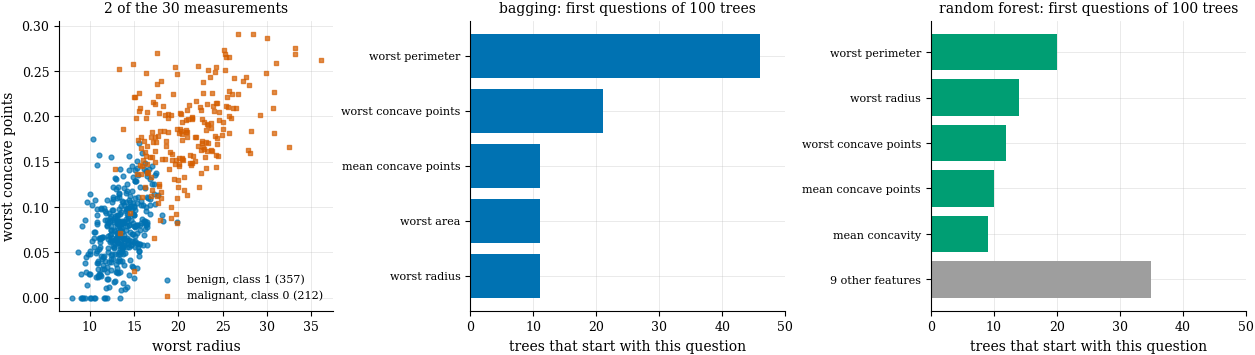

In [9]:
data = load_breast_cancer()
Xc, yc, feat = data.data, data.target, list(data.feature_names)      # target: 0 = malignant, 1 = benign
print(f"{Xc.shape[0]} tumors, {Xc.shape[1]} measurements each: "
      f"{np.sum(yc == 0)} malignant, {np.sum(yc == 1)} benign")

bagging = BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=100,
                            random_state=0).fit(Xc, yc)
forest = RandomForestClassifier(n_estimators=100, random_state=0).fit(Xc, yc)
roots = {}
for name, model in (("bagging", bagging), ("random forest", forest)):
    roots[name] = Counter(feat[tree.tree_.feature[0]] for tree in model.estimators_)
    top, n_top = roots[name].most_common(1)[0]
    print(f"{name:14s} {len(roots[name]):2d} different first questions; the most common, '{top}', "
          f"starts {n_top} of the 100 trees")

fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.6), gridspec_kw={"width_ratios": [1, 1.15, 1.15]})
a, b = feat.index("worst radius"), feat.index("worst concave points")
ax = axes[0]
ax.scatter(Xc[yc == 1, a], Xc[yc == 1, b], s=12, color=C0, alpha=0.7, label=f"benign, class 1 ({np.sum(yc == 1)})")
ax.scatter(Xc[yc == 0, a], Xc[yc == 0, b], s=12, color=C1, marker="s", alpha=0.7,
           label=f"malignant, class 0 ({np.sum(yc == 0)})")
ax.set_xlabel("worst radius"); ax.set_ylabel("worst concave points")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("2 of the 30 measurements", fontsize=10)
for ax, (name, col) in zip(axes[1:], (("bagging", C0), ("random forest", CG))):
    items = roots[name].most_common(5)
    rest = sum(roots[name].values()) - sum(v for _, v in items)
    if rest:                                                       # gather the rarer questions in one bar
        items.append((f"{len(roots[name]) - 5} other features", rest))
    ax.barh([k for k, _ in items][::-1], [v for _, v in items][::-1],
            color=[CX if k.endswith("other features") else col for k, _ in items][::-1])
    ax.set_xlim(0, 50)
    ax.set_xlabel("trees that start with this question")
    ax.set_title(f"{name}: first questions of 100 trees", fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
plt.show()

**Bagging:** 46 of the 100 trees ask the same first question ("worst perimeter"), and only 5 different
first questions appear. The same few strong features (the tumor's size, its concave points) win in
every bootstrap sample, so the trees look alike, and alike trees make the **same mistakes**, like voters
who copy each other. The random forest spreads its first question over 14 features; the most common one
starts only 20 of the 100 trees.

## 8. Why alike trees limit the team

Back to the noisy wave, and to the experiment that measures how much predictions **spread**: draw a
fresh dataset, fit, record the prediction at $x=1$; repeat 300 times. Three teams:

* **one tree**;
* **10 trees, each with its own fresh dataset** (the ideal: independent members);
* **bagging: 25 trees, all made from ONE dataset** by bootstrap (what we can do in practice).

The loop fits thousands of trees, so it takes about 15 seconds.

one tree                             spread 0.300
10 trees, each with its own data     spread 0.094
bagging: 25 trees from one dataset   spread 0.198


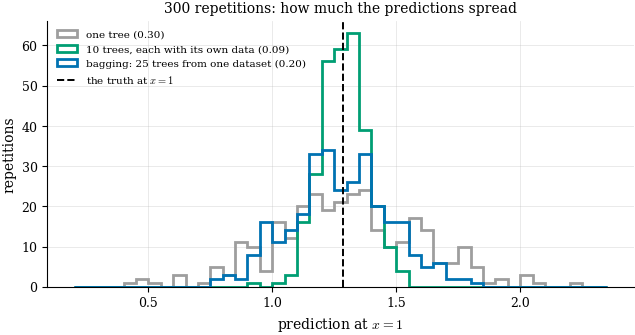

In [10]:
x0 = np.array([[1.0]])                       # the point where we watch the predictions
R = 300                                      # repetitions; each one draws 11 fresh datasets
rng = np.random.default_rng(11)
spread = {"one tree": [], "10 trees, each with its own data": [], "bagging: 25 trees from one dataset": []}
for r in range(R):
    preds = []
    for b in range(10):                      # 10 fresh datasets, one tree on each
        xr, yr = sample_noisy_wave(rng)
        preds.append(DecisionTreeRegressor(random_state=0).fit(xr[:, None], yr).predict(x0)[0])
    spread["one tree"].append(preds[0])
    spread["10 trees, each with its own data"].append(np.mean(preds))
    xr, yr = sample_noisy_wave(rng)          # ONE more dataset: bagging makes its 25 trees from it
    bagger = BaggingRegressor(DecisionTreeRegressor(random_state=0), n_estimators=25,
                              random_state=r).fit(xr[:, None], yr)
    spread["bagging: 25 trees from one dataset"].append(bagger.predict(x0)[0])

for name, v in spread.items():
    print(f"{name:36s} spread {np.std(v):.3f}")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
bins = np.arange(0.2, 2.4, 0.05)
for (name, v), c in zip(spread.items(), (CX, CG, C0)):
    ax.hist(v, bins=bins, histtype="step", lw=2, color=c, label=f"{name} ({np.std(v):.2f})")
ax.axvline(noisy_wave_truth(1.0), color="k", lw=1.4, ls="--", label="the truth at $x=1$")
ax.set_xlabel("prediction at $x=1$")
ax.set_ylabel("repetitions")
ax.legend(fontsize=7.5, loc="upper left")
ax.set_title(f"{R} repetitions: how much the predictions spread", fontsize=10)
plt.show()

One tree: spread 0.300. Ten trees with **their own** data: 0.094, about $0.300/\sqrt{10}$. Bagging, 25
trees from **one** dataset: the spread only falls to 0.198. The bagged trees share their data, so they
share part of their errors, and a shared error does not cancel; the box below shows why more trees
cannot remove it.

> **Going deeper.** If every pair of the $B$ members has correlation $\rho$, each with variance
> $\sigma^2$, their average has variance $\rho\,\sigma^2+\frac{1-\rho}{B}\,\sigma^2$. More trees shrink
> only the second term. The floor $\rho\,\sigma^2$ goes down only if the trees become **less alike**.

## 9. The random-forest trick: bench the star player

A **random forest** is bagging plus one change: at **every split**, the tree may look only at a
**random handful** of the features, and it picks the best question among those. Sometimes the star
feature is "on the bench", so other trees learn to use other clues. **The trick acts on the splits of a
tree, so a random forest works with trees only**; bagging works with any model. In scikit-learn the
handful is `max_features`; for classification the default is $\sqrt{p}$ of the $p$ features, here
$\sqrt{30}\approx5$ per split. (For regression, scikit-learn's default uses all $p$ features, which is
plain bagging: set `max_features` yourself, for example to $p/3$.)

**Does it help?** We compare bagging and a forest, 100 trees each, on 10 train/test splits of the breast
cancer data, from **5-fold cross-validation run twice** (the data is cut into 5 parts, each part is the
test set once, and the whole thing is repeated with another random cut), written as a small loop. For
each team we measure three things: how often two of its trees make the **same mistake** (of the patients
that at least one of two trees gets wrong, the share that both get wrong), the accuracy of **one tree**,
and the accuracy of the **team**.

(averages over the 10 splits)           bagging   forest
two trees make the same mistake           27.9%    25.1%
accuracy of one tree                      92.2%    92.0%
accuracy of the team                      95.6%    96.2%

the forest's trees share fewer mistakes in 10 of the 10 splits
the forest team is better in 7 splits, tied in 2, worse in 1


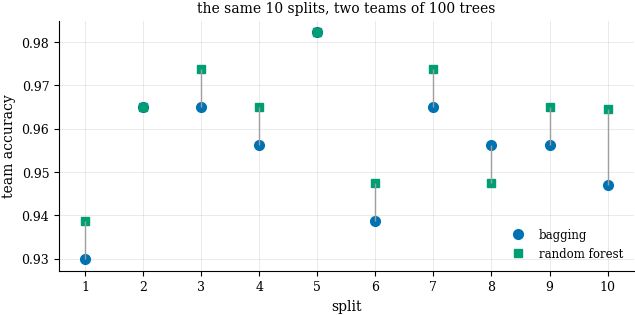

In [11]:
def tree_stats(model, X_test, y_test):
    "how often two trees make the same mistake (over all pairs), and the average accuracy of one tree"
    wrong = np.array([tree.predict(X_test) != y_test for tree in model.estimators_])
    shares = []
    for i, j in itertools.combinations(range(len(wrong)), 2):
        either = wrong[i] | wrong[j]
        if either.any():
            shares.append((wrong[i] & wrong[j]).sum() / either.sum())
    return np.mean(shares), 1 - wrong.mean()


MAX_FEATURES = "sqrt"                    # <-- CHANGE ME: 1, 5, 15 or 30 (30 = all of them: bagging again)
rows = []
splits = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0)
for train, test in splits.split(Xc, yc):
    bag = BaggingClassifier(DecisionTreeClassifier(random_state=0), n_estimators=100,
                            random_state=0).fit(Xc[train], yc[train])
    rf = RandomForestClassifier(n_estimators=100, max_features=MAX_FEATURES,
                                random_state=0).fit(Xc[train], yc[train])
    row = []
    for model in (bag, rf):
        row += [*tree_stats(model, Xc[test], yc[test]), model.score(Xc[test], yc[test])]
    rows.append(row)
rows = np.array(rows)                    # one row per split: bagging's 3 numbers, then the forest's 3

print(f"{'(averages over the 10 splits)':38s}{'bagging':>9s}{'forest':>9s}")
for k, name in enumerate(("two trees make the same mistake", "accuracy of one tree", "accuracy of the team")):
    print(f"{name:38s}{rows[:, k].mean():9.1%}{rows[:, k + 3].mean():9.1%}")
print(f"\nthe forest's trees share fewer mistakes in {np.sum(rows[:, 3] < rows[:, 0])} of the 10 splits")
print(f"the forest team is better in {np.sum(rows[:, 5] > rows[:, 2])} splits, tied in "
      f"{np.sum(rows[:, 5] == rows[:, 2])}, worse in {np.sum(rows[:, 5] < rows[:, 2])}")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
k = np.arange(1, 11)
ax.plot(k, rows[:, 2], "o", color=C0, ms=7, label="bagging")
ax.plot(k, rows[:, 5], "s", color=CG, ms=6, label="random forest")
ax.vlines(k, rows[:, 2], rows[:, 5], color=CX, lw=1)
ax.set_xticks(k)
ax.set_xlabel("split")
ax.set_ylabel("team accuracy")
ax.legend(fontsize=8.5, loc="lower right")
ax.set_title("the same 10 splits, two teams of 100 trees", fontsize=10)
plt.show()

The forest's trees are **not better** than bagging's (92.0% against 92.2% for one tree), they are **more
different**: of the patients that at least one of two forest trees gets wrong, both get wrong 25.1%,
against 27.9% for two bagged trees, lower in all 10 splits. So the vote corrects more mistakes, and the
forest team scores 96.2% against 95.6%: better in 7 splits, tied in 2. A modest gain here, at no cost,
which is why the random forest is the usual default.

## 10. Bonus: which measurements matter?

A forest also reports how much each feature **helped** its trees: the total improvement from every
question that used it, `feature_importances_` (they add up to 1). Here are the top eight for the forest
of section 7.

worst perimeter        0.174
worst radius           0.122
worst concave points   0.119


mean concave points    0.089
worst area             0.075
mean concavity         0.072
mean perimeter         0.054
mean area              0.045
(sum over all 30 features: 1.000)


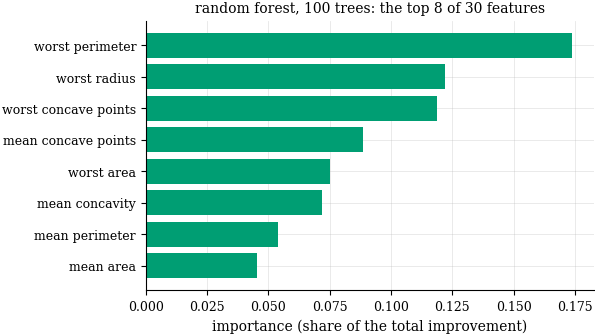

In [12]:
order = np.argsort(forest.feature_importances_)[::-1]
for k in order[:8]:
    print(f"{feat[k]:22s} {forest.feature_importances_[k]:.3f}")
print(f"(sum over all {len(feat)} features: {forest.feature_importances_.sum():.3f})")

fig, ax = plt.subplots(figsize=(6.0, 3.4))
top8 = order[:8][::-1]
ax.barh([feat[k] for k in top8], forest.feature_importances_[top8], color=CG)
ax.set_xlabel("importance (share of the total improvement)")
ax.set_title("random forest, 100 trees: the top 8 of 30 features", fontsize=10)
plt.show()

The ranking is a quick, free look inside the forest, with two cautions. Features that carry the same
information (radius, perimeter and area all measure size) **share** the credit, so each of them looks
less important than the information they carry. And "useful for prediction" is not "causes the
disease".

## Recap & exercises

**Recap.**

* **The bootstrap** draws $n$ examples with replacement from the one dataset. Each resample leaves out a
  bit over a third: 34.9% with ten examples, 36.8% with many.
* **Bagging** trains a model (usually a deep tree) on each bootstrap sample and lets them vote (or
  average); **any model** can go inside. Each member sees different data, so each makes different
  mistakes.
* **Out-of-bag:** each example is judged only by the trees that never saw it, a free validation set
  (moons: 0.9111 out-of-bag, 0.9083 on the test set; the hand-made version equals scikit-learn's).
* Bagging takes **any** model but helps only **unstable** ones: a deep tree's error fell on all 10
  training sets of the wave (by 55.7% on the first), a straight line's barely moved.
* **More trees never overfit:** the error settles (0.0413 at 100 trees, 0.0415 at 300). Tune the tree
  size, not the number of trees.
* **Alike trees limit the team:** 25 bagged trees from one dataset spread 0.198, against 0.094 for 10
  independent trees. On the real data, 46 of 100 bagged trees started with the same question.
* **A random forest** (**trees only**: its trick acts on a tree's splits) offers each split only a
  random handful of features, so its trees are more different (of the patients that two trees ever
  miss, both miss 25.1% instead of 27.9%) and the team is better (96.2% against 95.6%), while each tree
  is about as good.

**Check yourself.** Why does a random forest hide features at random: (a) to make each tree more
accurate, or (b) to make the trees more different from each other? Which numbers of section 9 answer
it?

**Exercises.**

1. In &sect;1, raise `n` to 100 and change the seed. What share of the cards does each of the three
   resamples leave out? Do the shares stay closer to the formula's than with ten cards?
2. In &sect;2, draw the five resamples with another seed (change `2489` in that cell). How many
   different first splits do you get? Is the out-of-bag score of &sect;3 still 7 of 10? (If some point is
   in every tree's sample, it has no judge at all, and the cell says so: what would you do with it?)
3. In &sect;4, set the team sizes to `(100, 1000)` (the cell then takes about 30 seconds). Over the 10
   draws, does the larger team ever lose? By how many test points at most?
4. In &sect;6, set `M = 1000`. From 100 trees on, does the test error climb steadily, as an overfitting
   model's would, or does it wobble inside a narrow band? How wide is the band?
5. In &sect;9, set `MAX_FEATURES` to 1, 5, 15 and 30. Watch the three rows. Which one goes down when the
   trees become more different? What happens to one tree's accuracy at `MAX_FEATURES = 1`, and to the
   team's?
6. **Write it yourself: bagging in ten lines.** Write `bag_predict(X_train, y_train, X_test, B, seed)`:
   draw `B` bootstrap samples with `np.random.default_rng(seed)`, fit a
   `DecisionTreeClassifier(random_state=0)` on each, and return the majority vote on `X_test`. Compare
   its test accuracy on the moons with `BaggingClassifier` for `B = 10` and `B = 100`. (The two need not
   agree exactly: their random draws differ.)